# 06_ROCOv2_VLM_Baseline

**Purpose:** Establish a zero-shot Vision-Language Model baseline
(BiomedCLIP) — the second baseline point in the research progression,
between the image-only DenseNet121 baseline (05) and the Proposed VLM
(07). This notebook trains **nothing**: it is a pure zero-shot evaluation.

### Methodology (confirmed, not assumed)
- **Checkpoint:** `hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224`,
  loaded via `open_clip`. Fixed and named explicitly — if unavailable, this
  notebook raises rather than silently substituting a different VLM.
- **Zero-shot classification:** each of the 18 labels is scored via cosine
  similarity between its image embedding and a fixed text-prompt embedding
  (`"a medical image showing {label}"`), scaled by BiomedCLIP's learned
  logit scale, then passed through a **per-label sigmoid** (not softmax —
  this is multi-label, not single-label multiclass, exactly as in
  Notebook 05).
- **No prompt tuning, no fine-tuning, no training of any kind.** The prompt
  template is fixed before ever touching Validation or Test — tuning it
  against either would defeat the purpose of a zero-shot baseline.
- **Primary threshold = 0.5**, fixed, for direct comparability with
  Notebook 05's DenseNet121 baseline (Part 13's convention). A documented
  caveat: zero-shot CLIP similarity-derived sigmoid scores are not
  guaranteed to be calibrated the way a trained classifier's sigmoid output
  is, so a **secondary** analysis also reports per-label thresholds
  optimized on **Validation only** (never Test) — reported separately,
  never conflated with the primary, comparable numbers.

### A deliberate deviation from Notebook 05's "reuse artifacts" convention
This notebook does **not** reuse Notebook 04's `preprocessing_config.json`
(target image size, channel normalization, tokenizer). BiomedCLIP requires
its own exact pretrained image transform and its own tokenizer — feeding it
DenseNet's ImageNet-style preprocessing would silently break its embedding
space. Using BiomedCLIP's own `preprocess`/tokenizer (from `open_clip`) is
the methodologically correct choice here, not an inconsistency.

### Inputs
- `Prepared/validation_prepared.csv`, `test_prepared.csv`, `label_mapping.json`
  (from Notebook 02). `train_prepared.csv` is read only for descriptive
  label-prevalence context — **no training images are read from Train at
  all**, since nothing is fit in this notebook.
- Original ROCOv2 Validation/Test image ZIPs (read-only).

### Outputs
16 artifacts under `Prepared/Baselines/BiomedCLIP_VLM_ZeroShot/`: config,
prompt templates, primary + secondary (threshold-optimized) metrics for
Validation and Test, per-label metrics, predictions, ROC/PR/confusion-matrix
figures (vector PDF + 300 DPI PNG), `reproducibility.json`,
`artifact_manifest.json`.

### Split roles
- **Train** — descriptive label-prevalence statistics only. Not used to fit
  anything (there is nothing to fit in zero-shot classification).
- **Validation** — used only for the secondary threshold-optimization
  analysis. Never used to tune the prompt template or the checkpoint choice.
- **Test** — final evaluation only, touched once, after every decision
  (checkpoint, prompt template, primary threshold) was already fixed.

### Non-goals (by design — see the Final Stop banner at the end)
No VLM training, no conformal prediction, no calibration split, no
counterfactual/XAI, no trust score. Those belong to later notebooks.

In [ ]:
# ============================================================
# CELL 1 — CONFIGURATION, PATHS, AND REPRODUCIBILITY
# ============================================================

import os
import io
import sys
import json
import time
import random
import shutil
import zipfile
import warnings
import platform
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    IN_COLAB = True
    print("Google Drive available.")
except ImportError:
    IN_COLAB = False
    print("Not running in Google Colab.")

# ------------------------------------------------------------
# Explicit project paths
# ------------------------------------------------------------
ROCO_ROOT = Path("/content/drive/MyDrive/ROCOv2")
PREPARED_DIR = ROCO_ROOT / "Prepared"

BASELINE_DIR = PREPARED_DIR / "Baselines" / "BiomedCLIP_VLM_ZeroShot"
FIG_DIR = BASELINE_DIR / "figures"
for d in [BASELINE_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

TRAIN_PREPARED_PATH = PREPARED_DIR / "train_prepared.csv"
VALID_PREPARED_PATH = PREPARED_DIR / "validation_prepared.csv"
TEST_PREPARED_PATH = PREPARED_DIR / "test_prepared.csv"
LABEL_MAPPING_PATH = PREPARED_DIR / "label_mapping.json"

IMAGE_ZIP_FILES = {
    "validation": ROCO_ROOT / "Validation" / "Images" / "valid_images.zip",
    "test": ROCO_ROOT / "Test" / "Images" / "test_images.zip",
}

# Outputs
CONFIG_PATH = BASELINE_DIR / "biomedclip_config.json"
PROMPTS_PATH = BASELINE_DIR / "biomedclip_prompt_templates.csv"
VAL_METRICS_PATH = BASELINE_DIR / "biomedclip_validation_metrics.csv"
TEST_METRICS_PATH = BASELINE_DIR / "biomedclip_test_metrics.csv"
VAL_METRICS_OPT_PATH = BASELINE_DIR / "biomedclip_validation_metrics_optimized_threshold.csv"
TEST_METRICS_OPT_PATH = BASELINE_DIR / "biomedclip_test_metrics_optimized_threshold.csv"
PER_LABEL_METRICS_PATH = BASELINE_DIR / "biomedclip_per_label_metrics.csv"
PREDICTIONS_PATH = BASELINE_DIR / "biomedclip_predictions.csv"
ROC_CURVES_PDF = FIG_DIR / "roc_curves.pdf"
ROC_CURVES_PNG = FIG_DIR / "roc_curves_300dpi.png"
PR_CURVES_PDF = FIG_DIR / "precision_recall_curves.pdf"
PR_CURVES_PNG = FIG_DIR / "precision_recall_curves_300dpi.png"
CM_PDF = FIG_DIR / "multilabel_confusion_matrices.pdf"
CM_PNG = FIG_DIR / "multilabel_confusion_matrices_300dpi.png"
REPRODUCIBILITY_PATH = BASELINE_DIR / "reproducibility.json"
MANIFEST_PATH = BASELINE_DIR / "artifact_manifest.json"
CORRUPT_SAMPLE_LOG_PATH = BASELINE_DIR / "corrupt_samples_skipped_during_evaluation.jsonl"

ALLOW_OVERWRITE = False

def safe_save_json(path, obj, allow_overwrite=None):
    allow_overwrite = ALLOW_OVERWRITE if allow_overwrite is None else allow_overwrite
    if path.exists() and not allow_overwrite:
        raise FileExistsError(
            f"Refusing to overwrite existing artifact:\n{path}\n\n"
            "Remove/rename it or explicitly set ALLOW_OVERWRITE=True after review."
        )
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, default=str)
    print("Saved:", path)

def safe_save_csv(path, df, allow_overwrite=None):
    allow_overwrite = ALLOW_OVERWRITE if allow_overwrite is None else allow_overwrite
    if path.exists() and not allow_overwrite:
        raise FileExistsError(
            f"Refusing to overwrite existing artifact:\n{path}\n\n"
            "Remove/rename it or explicitly set ALLOW_OVERWRITE=True after review."
        )
    df.to_csv(path, index=False)
    print("Saved:", path)

SEED = 42

def set_global_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed(seed)
            torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass

set_global_seed(SEED)

print("=" * 80)
print("NOTEBOOK 06 — BIOMEDCLIP VLM ZERO-SHOT BASELINE")
print("=" * 80)
print("ROCO_ROOT:", ROCO_ROOT)
print("BASELINE_DIR:", BASELINE_DIR)
print("Random seed:", SEED)


Mounted at /content/drive
Google Drive available.
NOTEBOOK 06 — BIOMEDCLIP VLM ZERO-SHOT BASELINE
ROCO_ROOT: /content/drive/MyDrive/ROCOv2
BASELINE_DIR: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_ZeroShot
Random seed: 42


## 1. Verify required inputs from Notebook 02

Only Notebook 02's outputs are required — this notebook does not depend on
Notebook 04's preprocessing config (see the deliberate-deviation note
above).

In [ ]:
# ============================================================
# CELL 2 — REQUIRED INPUT ARTIFACT CHECK
# ============================================================

required_inputs = {
    "train_prepared.csv": TRAIN_PREPARED_PATH,
    "validation_prepared.csv": VALID_PREPARED_PATH,
    "test_prepared.csv": TEST_PREPARED_PATH,
    "label_mapping.json": LABEL_MAPPING_PATH,
}

missing_inputs = [f"{name}: {path}" for name, path in required_inputs.items() if not path.exists()]

if missing_inputs:
    raise FileNotFoundError(
        "Required Notebook 06 input artifacts are missing:\n\n"
        + "\n".join(missing_inputs)
        + "\n\nRun 02_ROCOv2_Dataset_Preparation.ipynb first."
    )

for name, path in IMAGE_ZIP_FILES.items():
    if not path.exists():
        raise FileNotFoundError(f"Original image ZIP missing for {name}: {path}")

print("PASS — Required Notebook 02 artifacts and original Validation/Test image ZIPs exist.")
for name, path in required_inputs.items():
    print(f"{name:30s}: {path}")


PASS — Required Notebook 02 artifacts and original Validation/Test image ZIPs exist.
train_prepared.csv            : /content/drive/MyDrive/ROCOv2/Prepared/train_prepared.csv
validation_prepared.csv       : /content/drive/MyDrive/ROCOv2/Prepared/validation_prepared.csv
test_prepared.csv             : /content/drive/MyDrive/ROCOv2/Prepared/test_prepared.csv
label_mapping.json            : /content/drive/MyDrive/ROCOv2/Prepared/label_mapping.json


## 2. Load the authoritative split and label taxonomy

Same authoritative source as Notebook 05 — read from disk, never hardcoded.

In [ ]:
# ============================================================
# CELL 3 — LOAD SPLITS AND LABEL MAPPING
# ============================================================

split_dfs = {
    "train": pd.read_csv(TRAIN_PREPARED_PATH),
    "validation": pd.read_csv(VALID_PREPARED_PATH),
    "test": pd.read_csv(TEST_PREPARED_PATH),
}

with open(LABEL_MAPPING_PATH, "r", encoding="utf-8") as f:
    label_mapping = json.load(f)

assert len(label_mapping) == 18, "Authoritative label_mapping.json must contain exactly 18 labels."

LABEL_COLUMNS = [f"label_{cui}" for cui, _ in sorted(label_mapping.items(), key=lambda kv: kv[1])]
N_LABELS = len(LABEL_COLUMNS)

CANONICAL_LABEL_NAMES = {
    "C0000726": "Abdomen", "C0002978": "Angiogram", "C0006141": "Breast",
    "C0023216": "Lower Extremity", "C0024485": "Magnetic Resonance Imaging",
    "C0030797": "Pelvis", "C0032743": "Positron-Emission Tomography",
    "C0037303": "Bone structure of cranium", "C0037949": "Vertebral column",
    "C0040405": "X-Ray Computed Tomography", "C0041618": "Ultrasonography",
    "C0205106": "Transverse", "C0205129": "Sagittal", "C0817096": "Chest",
    "C1140618": "Upper Extremity", "C1306645": "Plain x-ray",
    "C1996865": "Postero-Anterior", "C1999039": "Anterior-Posterior",
}
LABEL_NAMES = [
    CANONICAL_LABEL_NAMES.get(cui, cui)
    for cui, _ in sorted(label_mapping.items(), key=lambda kv: kv[1])
]

print("=" * 80)
print("AUTHORITATIVE SPLIT (from disk)")
print("=" * 80)
for split_name, df in split_dfs.items():
    print(f"{split_name.capitalize():12s}: {len(df):,} rows")

print(f"\nLabel taxonomy ({N_LABELS} labels):")
for i, (col, name) in enumerate(zip(LABEL_COLUMNS, LABEL_NAMES)):
    print(f"  {i:02d} | {col} | {name}")


AUTHORITATIVE SPLIT (from disk)
Train       : 59,666 rows
Validation  : 9,819 rows
Test        : 9,870 rows

Label taxonomy (18 labels):
  00 | label_C0000726 | Abdomen
  01 | label_C0002978 | Angiogram
  02 | label_C0006141 | Breast
  03 | label_C0023216 | Lower Extremity
  04 | label_C0024485 | Magnetic Resonance Imaging
  05 | label_C0030797 | Pelvis
  06 | label_C0032743 | Positron-Emission Tomography
  07 | label_C0037303 | Bone structure of cranium
  08 | label_C0037949 | Vertebral column
  09 | label_C0040405 | X-Ray Computed Tomography
  10 | label_C0041618 | Ultrasonography
  11 | label_C0205106 | Transverse
  12 | label_C0205129 | Sagittal
  13 | label_C0817096 | Chest
  14 | label_C1140618 | Upper Extremity
  15 | label_C1306645 | Plain x-ray
  16 | label_C1996865 | Postero-Anterior
  17 | label_C1999039 | Anterior-Posterior


## 3. Descriptive label prevalence (Train) — context only, nothing is fit

Included for comparability with Notebook 05's class-imbalance table.
Zero-shot classification has no parameters to fit, so this is purely
descriptive — it does not influence the prompt template, the threshold, or
anything else in this notebook.

In [ ]:
# ============================================================
# CELL 4 — DESCRIPTIVE LABEL PREVALENCE (TRAIN, CONTEXT ONLY)
# ============================================================

train_label_matrix = split_dfs["train"][LABEL_COLUMNS].to_numpy(dtype=np.float64)
n_train = train_label_matrix.shape[0]
pos_counts = train_label_matrix.sum(axis=0)

prevalence_df = pd.DataFrame({
    "Label_Name": LABEL_NAMES,
    "Positive_Count_Train": pos_counts.astype(int),
    "Prevalence_Train": pos_counts / n_train,
}).sort_values("Positive_Count_Train", ascending=False).reset_index(drop=True)

display(prevalence_df)
print("(Descriptive only — not used to fit or tune anything in this notebook.)")


,Label_Name,Positive_Count_Train,Prevalence_Train
0,X-Ray Computed Tomography,20495,0.343495
1,Plain x-ray,16604,0.278282
2,Magnetic Resonance Imaging,9796,0.164181
3,Ultrasonography,8306,0.139208
4,Chest,7508,0.125834
5,Anterior-Posterior,7111,0.119180
6,Angiogram,3958,0.066336
7,Postero-Anterior,3393,0.056867
8,Bone structure of cranium,3326,0.055744
9,Abdomen,3176,0.053230


(Descriptive only — not used to fit or tune anything in this notebook.)


## 4. Load BiomedCLIP (fixed checkpoint — no silent substitution)

Matches the precedent set in Notebook 04 for the PubMedBERT tokenizer: if
this exact checkpoint is unavailable, the notebook stops rather than
silently falling back to a different VLM.

In [ ]:
# ============================================================
# CELL 5 — LOAD BIOMEDCLIP (fixed checkpoint)
# ============================================================

import torch
import torch.nn.functional as F

BIOMEDCLIP_CHECKPOINT = "hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224"

try:
    import open_clip
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "open_clip_torch"], check=True)
    import open_clip

try:
    biomedclip_model, biomedclip_preprocess = open_clip.create_model_from_pretrained(BIOMEDCLIP_CHECKPOINT)
    biomedclip_tokenizer = open_clip.get_tokenizer(BIOMEDCLIP_CHECKPOINT)
except Exception as exc:
    raise RuntimeError(
        f"Could not load the required VLM checkpoint '{BIOMEDCLIP_CHECKPOINT}'.\n"
        "This notebook does not silently fall back to a different VLM. Resolve "
        "connectivity/availability for this exact checkpoint before continuing.\n"
        f"Underlying error: {type(exc).__name__}: {exc}"
    )

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
biomedclip_model = biomedclip_model.to(device).eval()
for _p in biomedclip_model.parameters():
    _p.requires_grad = False  # zero-shot only — nothing in this notebook is trained

total_params = sum(p.numel() for p in biomedclip_model.parameters())

print("Loaded checkpoint:", BIOMEDCLIP_CHECKPOINT)
print("Device:", device)
print(f"Total parameters (frozen, zero-shot): {total_params:,}")
print("Image preprocessing: BiomedCLIP's own pretrained transform (NOT Notebook 04's).")
print(biomedclip_preprocess)


open_clip_config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

open_clip_pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  784MB            

open_clip_pytorch_model.bin: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/225k [00:00<?, ?B/s]

Loaded checkpoint: hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224
Device: cuda
Total parameters (frozen, zero-shot): 195,902,721
Image preprocessing: BiomedCLIP's own pretrained transform (NOT Notebook 04's).
Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    MaybeConvertMode()
    MaybeToTensor()
    Normalize(mean=[0.48145466, 0.4578275, 0.40821073], std=[0.26862954, 0.26130258, 0.27577711])
)


## 5. Local image extraction (proven pattern from Notebook 05)

Only Validation and Test ZIPs are extracted — Train images are never read
in this notebook, since nothing is fit here.

In [ ]:
# ============================================================
# CELL 6 — EXTRACT VALIDATION/TEST ZIPS TO PLAIN LOCAL FILES
# ============================================================

LOCAL_IMAGE_DIR = Path("/content/rocov2_images_local")
LOCAL_IMAGE_DIR.mkdir(parents=True, exist_ok=True)

EXTRACTED_IMAGE_DIRS = {
    split_name: LOCAL_IMAGE_DIR / f"{split_name}_extracted"
    for split_name in IMAGE_ZIP_FILES
}

def _extract_if_needed(zip_path, extract_dir, expected_members):
    extract_dir.mkdir(parents=True, exist_ok=True)
    existing = sum(1 for p in extract_dir.rglob("*") if p.is_file())
    if existing >= len(expected_members):
        print(f"Already extracted, skipping: {extract_dir} ({existing:,} files present)")
        return
    print(f"Extracting {zip_path.name} -> {extract_dir} ({len(expected_members):,} members)...")
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(extract_dir)
    extracted = sum(1 for p in extract_dir.rglob("*") if p.is_file())
    if extracted != len(expected_members):
        raise IOError(
            f"Extraction count mismatch for {zip_path.name}: expected "
            f"{len(expected_members):,}, found {extracted:,} under {extract_dir}."
        )
    print(f"  done: {extracted:,} files extracted.")

for split_name, zip_path in IMAGE_ZIP_FILES.items():
    with zipfile.ZipFile(zip_path, "r") as _zf:
        _members = [n for n in _zf.namelist() if not n.endswith("/")]
    _extract_if_needed(zip_path, EXTRACTED_IMAGE_DIRS[split_name], _members)

class LocalImageReader:
    def __init__(self, extract_dir):
        self.extract_dir = Path(extract_dir)

    def read_bytes(self, member):
        return (self.extract_dir / member).read_bytes()

image_readers = {
    split_name: LocalImageReader(EXTRACTED_IMAGE_DIRS[split_name])
    for split_name in IMAGE_ZIP_FILES
}

for split_name in IMAGE_ZIP_FILES:
    sample_row = split_dfs[split_name].iloc[0]
    raw = image_readers[split_name].read_bytes(sample_row["Image_Member"])
    assert len(raw) > 0, f"{split_name}: read zero bytes for {sample_row['Image_Member']}"

print("PASS — Local image reader verified on one sample per split.")


Extracting valid_images.zip -> /content/rocov2_images_local/validation_extracted (9,904 members)...
  done: 9,904 files extracted.
Extracting test_images.zip -> /content/rocov2_images_local/test_extracted (9,927 members)...
  done: 9,927 files extracted.
PASS — Local image reader verified on one sample per split.


## 6. Fixed zero-shot prompt template (decided before touching Validation/Test)

One template, applied uniformly to all 18 labels — no per-label tuning, no
ensembling, no optimization against any split. This is written to disk
immediately so the exact prompts used are part of the permanent record.

In [ ]:
# ============================================================
# CELL 7 — FIXED PROMPT TEMPLATE AND TEXT EMBEDDINGS
# ============================================================

PROMPT_TEMPLATE = "a medical image showing {label}"

label_prompts_df = pd.DataFrame({
    "Label_Name": LABEL_NAMES,
    "Prompt": [PROMPT_TEMPLATE.format(label=name.lower()) for name in LABEL_NAMES],
})
safe_save_csv(PROMPTS_PATH, label_prompts_df)
display(label_prompts_df)

with torch.no_grad():
    _text_tokens = biomedclip_tokenizer(label_prompts_df["Prompt"].tolist()).to(device)
    label_text_embeddings = biomedclip_model.encode_text(_text_tokens)
    label_text_embeddings = F.normalize(label_text_embeddings, dim=-1)

print(f"\nText embeddings shape: {tuple(label_text_embeddings.shape)}")


Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_ZeroShot/biomedclip_prompt_templates.csv


,Label_Name,Prompt
0,Abdomen,a medical image showing abdomen
1,Angiogram,a medical image showing angiogram
2,Breast,a medical image showing breast
3,Lower Extremity,a medical image showing lower extremity
4,Magnetic Resonance Imaging,a medical image showing magnetic resonance ima...
5,Pelvis,a medical image showing pelvis
6,Positron-Emission Tomography,a medical image showing positron-emission tomo...
7,Bone structure of cranium,a medical image showing bone structure of cranium
8,Vertebral column,a medical image showing vertebral column
9,X-Ray Computed Tomography,a medical image showing x-ray computed tomography



Text embeddings shape: (18, 512)


## 7. Zero-shot inference

Cosine similarity between each image embedding and each label's text
embedding, scaled by BiomedCLIP's own learned logit scale, then a
**per-label sigmoid** — never softmax, since labels are not mutually
exclusive.

In [ ]:
# ============================================================
# CELL 8 — ZERO-SHOT INFERENCE FUNCTION
# ============================================================

from PIL import Image
from torch.utils.data import Dataset, DataLoader

# Fresh log for this run only — unlike Notebook 05's checkpoint-resumable
# training loop, this notebook runs start-to-finish in one pass, so an
# append-forever log would risk the same stale-count confusion encountered
# there. Cleared once, here, before any evaluation runs.
if CORRUPT_SAMPLE_LOG_PATH.exists():
    CORRUPT_SAMPLE_LOG_PATH.unlink()

def _append_corrupt_sample_log(record):
    with open(CORRUPT_SAMPLE_LOG_PATH, "a", encoding="utf-8") as f:
        f.write(json.dumps(record, default=str) + "\n")

class ROCOv2ZeroShotDataset(Dataset):
    def __init__(self, df, split_name, image_reader, transform, label_columns, max_retries=5):
        self.df = df.reset_index(drop=True)
        self.split_name = split_name
        self.image_reader = image_reader
        self.transform = transform
        self.label_columns = label_columns
        self.max_retries = max_retries

    def __len__(self):
        return len(self.df)

    def _load_item(self, idx):
        row = self.df.iloc[idx]
        raw_bytes = self.image_reader.read_bytes(row["Image_Member"])
        with Image.open(io.BytesIO(raw_bytes)) as img:
            image = self.transform(img.convert("RGB"))
        labels = torch.tensor(row[self.label_columns].to_numpy(dtype=np.float32), dtype=torch.float32)
        return image, labels, row["ID"]

    def __getitem__(self, idx):
        tried_idx = idx
        last_exc = None
        for attempt in range(self.max_retries + 1):
            try:
                return self._load_item(tried_idx)
            except Exception as exc:
                last_exc = exc
                bad_id = self.df.iloc[tried_idx]["ID"]
                print(f"WARNING — [{self.split_name}] unreadable sample skipped: "
                      f"ID={bad_id} ({type(exc).__name__}: {exc}). "
                      f"Substituting a different sample (attempt {attempt + 1}/{self.max_retries}).")
                _append_corrupt_sample_log({
                    "Split": self.split_name, "ID": str(bad_id),
                    "Error": f"{type(exc).__name__}: {exc}", "Timestamp": time.time(),
                })
                tried_idx = random.randrange(len(self.df))
        raise RuntimeError(
            f"[{self.split_name}] Exceeded max_retries={self.max_retries} while searching "
            f"for a readable sample near index {idx}. Last error: {type(last_exc).__name__}: {last_exc}"
        )


@torch.no_grad()
def run_zero_shot(split_name, batch_size=32, num_workers=2):
    dataset = ROCOv2ZeroShotDataset(
        split_dfs[split_name], split_name, image_readers[split_name], biomedclip_preprocess, LABEL_COLUMNS
    )
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)

    all_true, all_score, all_ids = [], [], []
    logit_scale = biomedclip_model.logit_scale.exp()

    for images, labels, ids in loader:
        images = images.to(device)
        image_embeddings = biomedclip_model.encode_image(images)
        image_embeddings = F.normalize(image_embeddings, dim=-1)

        logits = logit_scale * image_embeddings @ label_text_embeddings.T
        scores = torch.sigmoid(logits).cpu().numpy()

        all_true.append(labels.numpy())
        all_score.append(scores)
        all_ids.extend(list(ids))

    y_true = np.concatenate(all_true)
    y_score = np.concatenate(all_score)
    return y_true, y_score, all_ids

print("run_zero_shot() defined — cosine similarity -> logit_scale -> per-label sigmoid, no softmax.")


run_zero_shot() defined — cosine similarity -> logit_scale -> per-label sigmoid, no softmax.


## 8. Full multi-label evaluation function (same design as Notebook 05)

Reported metrics match Notebook 05 exactly, for direct baseline-to-baseline
comparability. NaN-safe for labels with insufficient support — reported,
never silently dropped.

In [ ]:
# ============================================================
# CELL 9 — FULL MULTI-LABEL EVALUATION FUNCTION
# ============================================================

from sklearn.metrics import (
    precision_recall_fscore_support, roc_auc_score, average_precision_score,
    hamming_loss, accuracy_score, multilabel_confusion_matrix,
)

def full_multilabel_evaluation(y_true, y_score, threshold, label_names):
    if np.isscalar(threshold):
        threshold_arr = np.full(y_true.shape[1], threshold, dtype=np.float64)
    else:
        threshold_arr = np.asarray(threshold, dtype=np.float64)

    y_pred = (y_score >= threshold_arr[np.newaxis, :]).astype(int)
    n_labels = y_true.shape[1]

    micro_p, micro_r, micro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="micro", zero_division=0)
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0)
    _, _, weighted_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0)

    per_label_p, per_label_r, per_label_f1, per_label_support = precision_recall_fscore_support(
        y_true, y_pred, average=None, zero_division=0)

    hamming = hamming_loss(y_true, y_pred)
    subset_acc = accuracy_score(y_true, y_pred)

    per_label_roc_auc, per_label_pr_auc = [], []
    for c in range(n_labels):
        col_true = y_true[:, c]
        if len(np.unique(col_true)) < 2:
            per_label_roc_auc.append(np.nan)
            per_label_pr_auc.append(np.nan)
            continue
        per_label_roc_auc.append(roc_auc_score(col_true, y_score[:, c]))
        per_label_pr_auc.append(average_precision_score(col_true, y_score[:, c]))

    degenerate_labels = [label_names[c] for c in range(n_labels) if np.isnan(per_label_roc_auc[c])]

    try:
        micro_roc_auc = roc_auc_score(y_true, y_score, average="micro")
    except ValueError:
        micro_roc_auc = np.nan
    macro_roc_auc = float(np.nanmean(per_label_roc_auc)) if not all(np.isnan(per_label_roc_auc)) else np.nan

    try:
        micro_pr_auc = average_precision_score(y_true, y_score, average="micro")
    except ValueError:
        micro_pr_auc = np.nan
    macro_pr_auc = float(np.nanmean(per_label_pr_auc)) if not all(np.isnan(per_label_pr_auc)) else np.nan

    overall = {
        "Micro_Precision": micro_p, "Micro_Recall": micro_r, "Micro_F1": micro_f1,
        "Macro_Precision": macro_p, "Macro_Recall": macro_r, "Macro_F1": macro_f1,
        "Weighted_F1": weighted_f1, "Hamming_Loss": hamming, "Subset_Accuracy": subset_acc,
        "ROC_AUC_Micro": micro_roc_auc, "ROC_AUC_Macro": macro_roc_auc,
        "PR_AUC_Micro": micro_pr_auc, "PR_AUC_Macro": macro_pr_auc,
        "N_Samples": int(y_true.shape[0]),
        "Labels_With_Insufficient_Support": ", ".join(degenerate_labels) if degenerate_labels else "none",
    }

    per_label = pd.DataFrame({
        "Label_Name": label_names,
        "Precision": per_label_p, "Recall": per_label_r, "F1": per_label_f1,
        "Support": per_label_support, "ROC_AUC": per_label_roc_auc, "PR_AUC": per_label_pr_auc,
    })

    return overall, per_label, y_pred

print("full_multilabel_evaluation() defined.")


full_multilabel_evaluation() defined.


## 9. Run zero-shot on Validation (primary, threshold = 0.5)

Threshold-free metrics (ROC-AUC, PR-AUC) are the most meaningful zero-shot
numbers here; the fixed 0.5 threshold is reported primarily for direct
comparability with Notebook 05, with the calibration caveat noted above.

In [ ]:
# ============================================================
# CELL 10 — VALIDATION: PRIMARY ZERO-SHOT EVALUATION (threshold = 0.5)
# ============================================================

PRIMARY_THRESHOLD = 0.5

val_y_true, val_y_score, val_ids = run_zero_shot("validation")
val_overall, val_per_label, val_y_pred = full_multilabel_evaluation(
    val_y_true, val_y_score, PRIMARY_THRESHOLD, LABEL_NAMES,
)
val_overall["Threshold"] = "0.5 (fixed, primary)"
val_per_label.insert(0, "Split", "validation")
val_per_label.insert(1, "Threshold_Type", "primary_0.5")

val_metrics_df = pd.DataFrame([val_overall])
safe_save_csv(VAL_METRICS_PATH, val_metrics_df)

print("VALIDATION METRICS (primary, threshold=0.5):")
display(val_metrics_df)


Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_ZeroShot/biomedclip_validation_metrics.csv
VALIDATION METRICS (primary, threshold=0.5):


,Micro_Precision,Micro_Recall,Micro_F1,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Hamming_Loss,Subset_Accuracy,ROC_AUC_Micro,ROC_AUC_Macro,PR_AUC_Micro,PR_AUC_Macro,N_Samples,Labels_With_Insufficient_Support,Threshold
0,0.087636,0.999935,0.161149,0.087614,0.999859,0.1479,0.31193,0.9119,0.0,0.679915,0.66667,0.131753,0.122874,9819,none,"0.5 (fixed, primary)"


## 10. FINAL TEST EVALUATION (primary, threshold = 0.5) — Test touched here only

Only after the checkpoint, prompt template, and primary threshold were all
fixed in advance is Test evaluated.

In [ ]:
# ============================================================
# CELL 11 — FINAL TEST EVALUATION (TEST TOUCHED HERE FOR THE FIRST TIME)
# ============================================================

print("=" * 80)
print("FINAL TEST EVALUATION — TEST SET TOUCHED FOR THE FIRST AND ONLY TIME HERE")
print("=" * 80)

test_y_true, test_y_score, test_ids = run_zero_shot("test")
test_overall, test_per_label, test_y_pred = full_multilabel_evaluation(
    test_y_true, test_y_score, PRIMARY_THRESHOLD, LABEL_NAMES,
)
test_overall["Threshold"] = "0.5 (fixed, primary)"
test_per_label.insert(0, "Split", "test")
test_per_label.insert(1, "Threshold_Type", "primary_0.5")

test_metrics_df = pd.DataFrame([test_overall])
safe_save_csv(TEST_METRICS_PATH, test_metrics_df)

print("\nFINAL TEST RESULTS (primary, threshold=0.5):")
display(test_metrics_df)


FINAL TEST EVALUATION — TEST SET TOUCHED FOR THE FIRST AND ONLY TIME HERE
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_ZeroShot/biomedclip_test_metrics.csv

FINAL TEST RESULTS (primary, threshold=0.5):


,Micro_Precision,Micro_Recall,Micro_F1,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Hamming_Loss,Subset_Accuracy,ROC_AUC_Micro,ROC_AUC_Macro,PR_AUC_Micro,PR_AUC_Macro,N_Samples,Labels_With_Insufficient_Support,Threshold
0,0.0878,0.999936,0.161425,0.087776,0.999858,0.148385,0.309536,0.91177,0.0,0.67835,0.664458,0.131482,0.122955,9870,none,"0.5 (fixed, primary)"


## 11. Secondary analysis — per-label thresholds optimized on Validation only

Sweeps a threshold grid **on Validation only** to maximize each label's F1,
then applies those fixed thresholds to Test. Reported as a clearly separate,
secondary result set — never used to revise the primary numbers above, and
Test is never used to pick these thresholds.

In [ ]:
# ============================================================
# CELL 12 — SECONDARY: VALIDATION-OPTIMIZED PER-LABEL THRESHOLDS
# ============================================================

from sklearn.metrics import f1_score

threshold_grid = np.arange(0.05, 0.96, 0.01)
optimized_thresholds = np.full(N_LABELS, PRIMARY_THRESHOLD, dtype=np.float64)
threshold_search_rows = []

for c in range(N_LABELS):
    col_true = val_y_true[:, c]
    if len(np.unique(col_true)) < 2:
        threshold_search_rows.append({
            "Label_Name": LABEL_NAMES[c], "Optimized_Threshold": PRIMARY_THRESHOLD,
            "Validation_F1_At_Optimized": np.nan,
            "Note": "insufficient positive/negative support in Validation — kept at primary 0.5",
        })
        continue
    col_score = val_y_score[:, c]
    f1s = [f1_score(col_true, (col_score >= t).astype(int), zero_division=0) for t in threshold_grid]
    best_idx = int(np.argmax(f1s))
    optimized_thresholds[c] = threshold_grid[best_idx]
    threshold_search_rows.append({
        "Label_Name": LABEL_NAMES[c], "Optimized_Threshold": threshold_grid[best_idx],
        "Validation_F1_At_Optimized": f1s[best_idx], "Note": "",
    })

threshold_search_df = pd.DataFrame(threshold_search_rows)
display(threshold_search_df)

val_overall_opt, val_per_label_opt, _ = full_multilabel_evaluation(
    val_y_true, val_y_score, optimized_thresholds, LABEL_NAMES)
val_overall_opt["Threshold"] = "Validation-optimized per-label (secondary)"
safe_save_csv(VAL_METRICS_OPT_PATH, pd.DataFrame([val_overall_opt]))

test_overall_opt, test_per_label_opt, test_y_pred_opt = full_multilabel_evaluation(
    test_y_true, test_y_score, optimized_thresholds, LABEL_NAMES)
test_overall_opt["Threshold"] = "Validation-optimized per-label (secondary)"
safe_save_csv(TEST_METRICS_OPT_PATH, pd.DataFrame([test_overall_opt]))

val_per_label_opt.insert(0, "Split", "validation")
val_per_label_opt.insert(1, "Threshold_Type", "validation_optimized")
test_per_label_opt.insert(0, "Split", "test")
test_per_label_opt.insert(1, "Threshold_Type", "validation_optimized")

per_label_metrics_df = pd.concat(
    [val_per_label, test_per_label, val_per_label_opt, test_per_label_opt], ignore_index=True)
safe_save_csv(PER_LABEL_METRICS_PATH, per_label_metrics_df)

print("\nSECONDARY — Validation-optimized thresholds applied to Test:")
display(pd.DataFrame([test_overall_opt]))


,Label_Name,Optimized_Threshold,Validation_F1_At_Optimized,Note
0,Abdomen,0.95,0.105059,
1,Angiogram,0.87,0.082235,
2,Breast,0.95,0.008139,
3,Lower Extremity,0.95,0.086066,
4,Magnetic Resonance Imaging,0.95,0.257257,
5,Pelvis,0.95,0.090971,
6,Positron-Emission Tomography,0.95,0.014073,
7,Bone structure of cranium,0.43,0.077489,
8,Vertebral column,0.95,0.036889,
9,X-Ray Computed Tomography,0.90,0.545643,


Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_ZeroShot/biomedclip_validation_metrics_optimized_threshold.csv
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_ZeroShot/biomedclip_test_metrics_optimized_threshold.csv
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_ZeroShot/biomedclip_per_label_metrics.csv

SECONDARY — Validation-optimized thresholds applied to Test:


,Micro_Precision,Micro_Recall,Micro_F1,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Hamming_Loss,Subset_Accuracy,ROC_AUC_Micro,ROC_AUC_Macro,PR_AUC_Micro,PR_AUC_Macro,N_Samples,Labels_With_Insufficient_Support,Threshold
0,0.088007,0.999936,0.161775,0.087883,0.999858,0.148562,0.309723,0.909417,0.0,0.67835,0.664458,0.131482,0.122955,9870,none,Validation-optimized per-label (secondary)


## 12. Save predictions

In [ ]:
# ============================================================
# CELL 13 — SAVE PREDICTIONS (VALIDATION + TEST)
# ============================================================

def build_predictions_df(split_name, ids, y_true, y_score, y_pred_primary, y_pred_opt):
    rows = {"ID": ids, "Split": split_name}
    for i, col in enumerate(LABEL_COLUMNS):
        rows[f"{col}_true"] = y_true[:, i]
        rows[f"{col}_score"] = y_score[:, i]
        rows[f"{col}_pred_primary_0.5"] = y_pred_primary[:, i]
        rows[f"{col}_pred_validation_optimized"] = y_pred_opt[:, i]
    return pd.DataFrame(rows)

_, _, val_y_pred_opt = full_multilabel_evaluation(val_y_true, val_y_score, optimized_thresholds, LABEL_NAMES)

predictions_df = pd.concat([
    build_predictions_df("validation", val_ids, val_y_true, val_y_score, val_y_pred, val_y_pred_opt),
    build_predictions_df("test", test_ids, test_y_true, test_y_score, test_y_pred, test_y_pred_opt),
], ignore_index=True)

safe_save_csv(PREDICTIONS_PATH, predictions_df)


Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_ZeroShot/biomedclip_predictions.csv


## 13. Publication-quality ROC curves (Test, primary threshold's underlying scores)

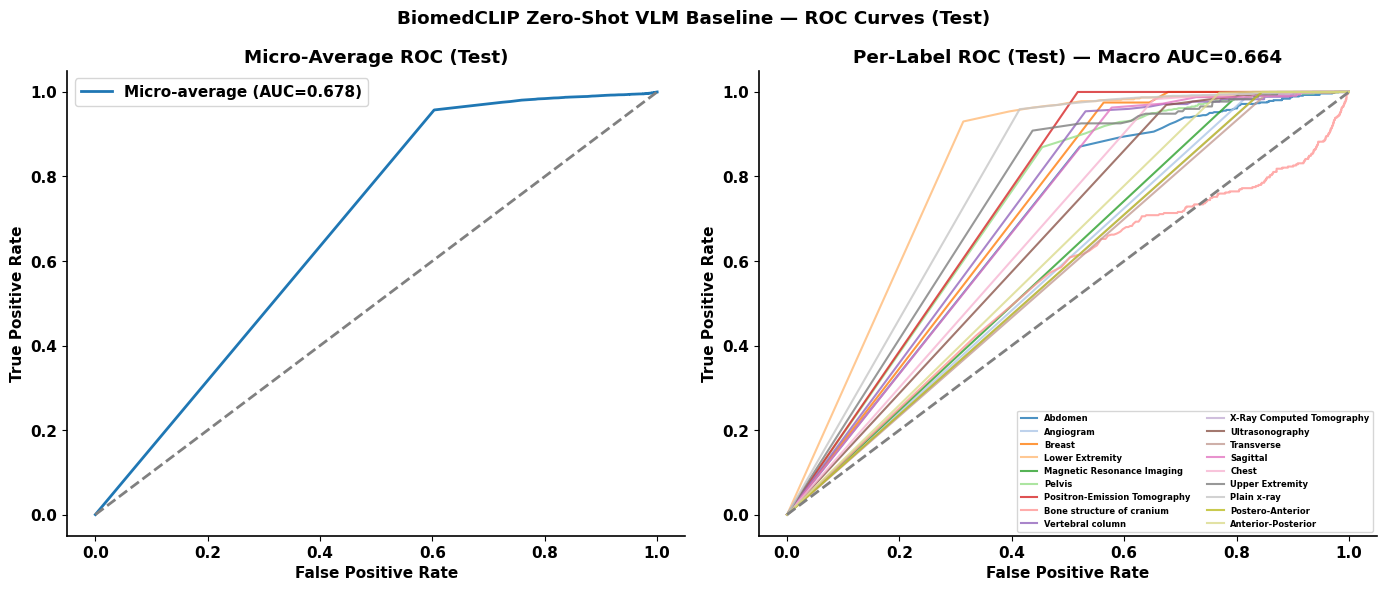

Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_ZeroShot/figures/roc_curves.pdf
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_ZeroShot/figures/roc_curves_300dpi.png


In [ ]:
# ============================================================
# CELL 14 — ROC CURVES FIGURE (TEST)
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

plt.rcParams.update({
    "font.weight": "bold", "axes.labelweight": "bold", "axes.titleweight": "bold",
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.size": 11, "axes.linewidth": 1.2, "lines.linewidth": 2.0,
})

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

fpr_micro, tpr_micro, _ = roc_curve(test_y_true.ravel(), test_y_score.ravel())
axes[0].plot(fpr_micro, tpr_micro, color="#1f77b4",
             label=f"Micro-average (AUC={test_overall['ROC_AUC_Micro']:.3f})")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("Micro-Average ROC (Test)"); axes[0].legend(frameon=True)

cmap = plt.get_cmap("tab20")
for c in range(N_LABELS):
    if len(np.unique(test_y_true[:, c])) < 2:
        continue
    fpr_c, tpr_c, _ = roc_curve(test_y_true[:, c], test_y_score[:, c])
    axes[1].plot(fpr_c, tpr_c, color=cmap(c % 20), alpha=0.8, linewidth=1.5, label=LABEL_NAMES[c])
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].set_title(f"Per-Label ROC (Test) — Macro AUC={test_overall['ROC_AUC_Macro']:.3f}")
axes[1].legend(fontsize=6, ncol=2, frameon=True, loc="lower right")

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle("BiomedCLIP Zero-Shot VLM Baseline — ROC Curves (Test)", fontweight="bold")
fig.tight_layout()
fig.savefig(ROC_CURVES_PDF, format="pdf", bbox_inches="tight")
fig.savefig(ROC_CURVES_PNG, format="png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", ROC_CURVES_PDF)
print("Saved:", ROC_CURVES_PNG)


## 14. Publication-quality Precision-Recall curves (Test)

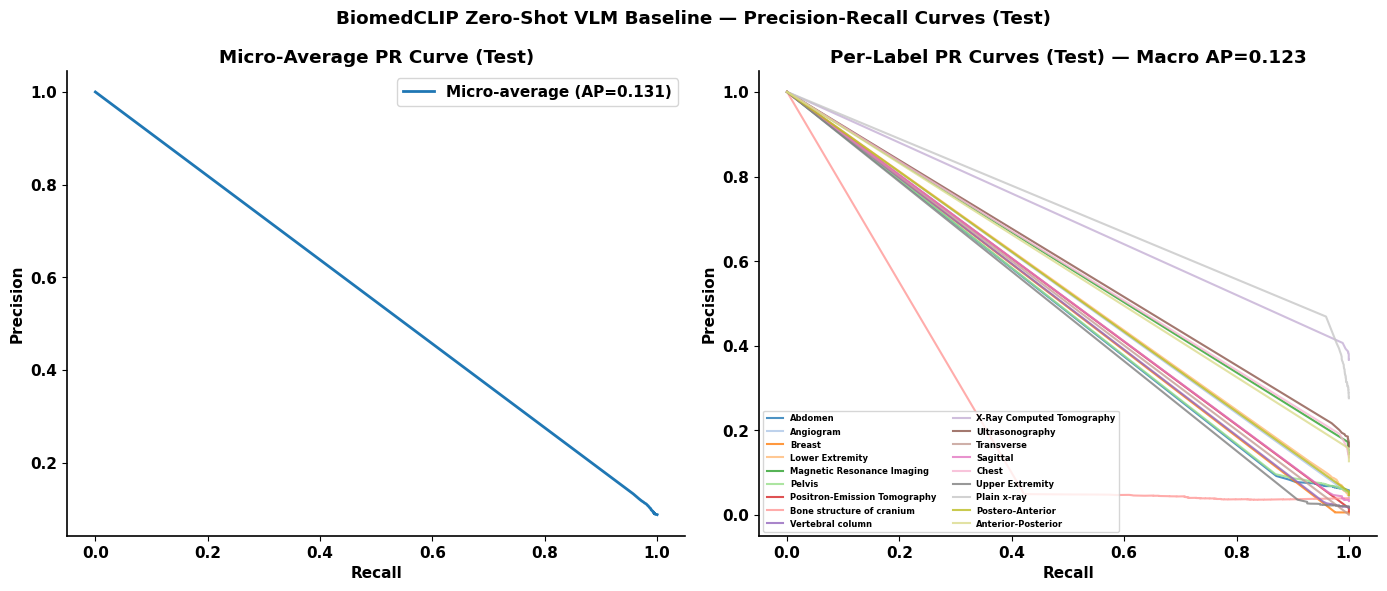

Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_ZeroShot/figures/precision_recall_curves.pdf
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_ZeroShot/figures/precision_recall_curves_300dpi.png


In [ ]:
# ============================================================
# CELL 15 — PRECISION-RECALL CURVES FIGURE (TEST)
# ============================================================

from sklearn.metrics import precision_recall_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

prec_micro, rec_micro, _ = precision_recall_curve(test_y_true.ravel(), test_y_score.ravel())
axes[0].plot(rec_micro, prec_micro, color="#1f77b4",
             label=f"Micro-average (AP={test_overall['PR_AUC_Micro']:.3f})")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision")
axes[0].set_title("Micro-Average PR Curve (Test)"); axes[0].legend(frameon=True)

for c in range(N_LABELS):
    if len(np.unique(test_y_true[:, c])) < 2:
        continue
    prec_c, rec_c, _ = precision_recall_curve(test_y_true[:, c], test_y_score[:, c])
    axes[1].plot(rec_c, prec_c, color=cmap(c % 20), alpha=0.8, linewidth=1.5, label=LABEL_NAMES[c])
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title(f"Per-Label PR Curves (Test) — Macro AP={test_overall['PR_AUC_Macro']:.3f}")
axes[1].legend(fontsize=6, ncol=2, frameon=True, loc="lower left")

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle("BiomedCLIP Zero-Shot VLM Baseline — Precision-Recall Curves (Test)", fontweight="bold")
fig.tight_layout()
fig.savefig(PR_CURVES_PDF, format="pdf", bbox_inches="tight")
fig.savefig(PR_CURVES_PNG, format="png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", PR_CURVES_PDF)
print("Saved:", PR_CURVES_PNG)


## 15. Multi-label confusion matrices (Test, primary threshold = 0.5)

One 2x2 matrix per label — not a single 18-class matrix, since this is
multi-label.

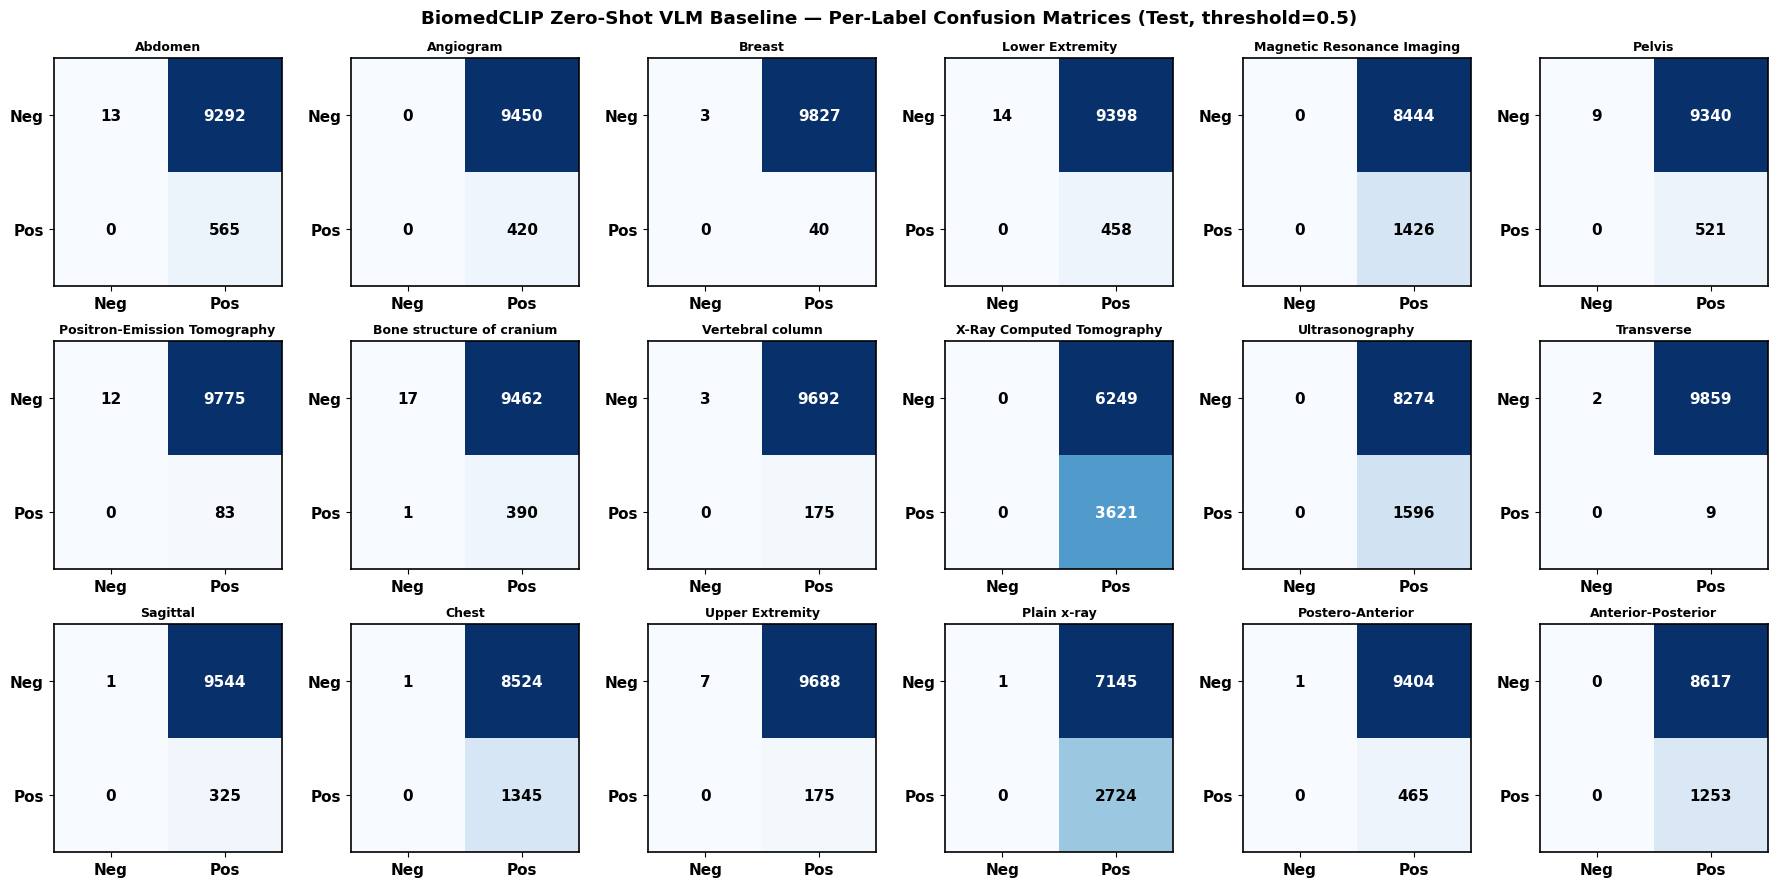

Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_ZeroShot/figures/multilabel_confusion_matrices.pdf
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_ZeroShot/figures/multilabel_confusion_matrices_300dpi.png


In [ ]:
# ============================================================
# CELL 16 — MULTI-LABEL CONFUSION MATRICES FIGURE (TEST)
# ============================================================

cm_array = multilabel_confusion_matrix(test_y_true, test_y_pred)

n_cols = 6
n_rows = int(np.ceil(N_LABELS / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 3 * n_rows))
axes = axes.flatten()

for c in range(N_LABELS):
    ax = axes[c]
    cm = cm_array[c]
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontweight="bold")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["Neg", "Pos"]); ax.set_yticklabels(["Neg", "Pos"])
    ax.set_title(LABEL_NAMES[c], fontsize=9)

for c in range(N_LABELS, len(axes)):
    axes[c].axis("off")

fig.suptitle("BiomedCLIP Zero-Shot VLM Baseline — Per-Label Confusion Matrices (Test, threshold=0.5)",
              fontweight="bold")
fig.tight_layout()
fig.savefig(CM_PDF, format="pdf", bbox_inches="tight")
fig.savefig(CM_PNG, format="png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", CM_PDF)
print("Saved:", CM_PNG)


## 16. Save configuration and reproducibility record

In [ ]:
# ============================================================
# CELL 17 — SAVE CONFIG AND REPRODUCIBILITY.JSON
# ============================================================

biomedclip_config = {
    "checkpoint": BIOMEDCLIP_CHECKPOINT,
    "methodology": "zero-shot classification (no training, no fine-tuning)",
    "prompt_template": PROMPT_TEMPLATE,
    "scoring": "sigmoid(logit_scale * cosine_similarity) per label, independent (no softmax)",
    "primary_threshold": PRIMARY_THRESHOLD,
    "primary_threshold_note": (
        "Fixed at 0.5 for direct comparability with Notebook 05's DenseNet121 "
        "baseline. Zero-shot CLIP similarity scores are not guaranteed to be "
        "calibrated the way a trained classifier's sigmoid output is."
    ),
    "secondary_threshold_strategy": (
        "Per-label thresholds maximizing F1 on Validation only (grid 0.05-0.95, "
        "step 0.01), applied unchanged to Test. Never tuned on Test."
    ),
    "optimized_thresholds_per_label": {
        name: float(t) for name, t in zip(LABEL_NAMES, optimized_thresholds)
    },
    "label_columns": LABEL_COLUMNS,
    "label_names": LABEL_NAMES,
    "split_sizes": {k: int(len(v)) for k, v in split_dfs.items()},
    "images_used_from": "validation and test only — train images were never read",
}
safe_save_json(CONFIG_PATH, biomedclip_config)

def package_version(module_name):
    try:
        module = __import__(module_name)
        return getattr(module, "__version__", "unknown")
    except Exception:
        return "not installed"

reproducibility = {
    "notebook": "06_ROCOv2_VLM_Baseline",
    "python_version": sys.version,
    "platform": platform.platform(),
    "pytorch_version": torch.__version__,
    "open_clip_version": package_version("open_clip"),
    "sklearn_version": package_version("sklearn"),
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "cuda_version": torch.version.cuda if torch.cuda.is_available() else None,
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "random_seed": SEED,
    "checkpoint": BIOMEDCLIP_CHECKPOINT,
    "training_performed": False,
}
safe_save_json(REPRODUCIBILITY_PATH, reproducibility)


Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_ZeroShot/biomedclip_config.json
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_ZeroShot/reproducibility.json


## 17. Calibration warning — same status as Notebook 05

Validation is used here for the secondary threshold-optimization pass —
still development usage, not an independent conformal calibration set.

In [ ]:
# ============================================================
# CELL 18 — CALIBRATION STATUS WARNING
# ============================================================

print("=" * 80)
print("CALIBRATION STATUS — READ BEFORE PROCEEDING TO CONFORMAL PREDICTION")
print("=" * 80)
print('''
Current dataset: Train / Validation / Test only.
There is currently NO independent Calibration split.

Validation in THIS notebook was used for:
  - secondary per-label threshold optimization (F1-maximizing grid search)

This is still a development use of Validation, even though no model
parameters were fit. Validation should NOT automatically be treated as an
independent Conformal Prediction calibration set.

No Calibration split is created in this notebook. The Conformal Prediction
notebook must establish its own calibration strategy before running any
conformal experiments (see Notebook 05's identical warning for the two
candidate strategies under consideration).
''')


CALIBRATION STATUS — READ BEFORE PROCEEDING TO CONFORMAL PREDICTION

Current dataset: Train / Validation / Test only.
There is currently NO independent Calibration split.

Validation in THIS notebook was used for:
  - secondary per-label threshold optimization (F1-maximizing grid search)

This is still a development use of Validation, even though no model
parameters were fit. Validation should NOT automatically be treated as an
independent Conformal Prediction calibration set.

No Calibration split is created in this notebook. The Conformal Prediction
notebook must establish its own calibration strategy before running any
conformal experiments (see Notebook 05's identical warning for the two
candidate strategies under consideration).



## 18. Artifact manifest and final report

In [ ]:
# ============================================================
# CELL 19 — ARTIFACT MANIFEST + FINAL REPORT
# ============================================================

artifact_paths = [
    CONFIG_PATH, PROMPTS_PATH, VAL_METRICS_PATH, TEST_METRICS_PATH,
    VAL_METRICS_OPT_PATH, TEST_METRICS_OPT_PATH, PER_LABEL_METRICS_PATH,
    PREDICTIONS_PATH, ROC_CURVES_PDF, ROC_CURVES_PNG, PR_CURVES_PDF, PR_CURVES_PNG,
    CM_PDF, CM_PNG, REPRODUCIBILITY_PATH,
]

manifest = [{
    "Artifact": p.name, "Path": str(p), "Exists": p.exists(),
    "Size_KB": round(p.stat().st_size / 1024, 2) if p.exists() else None,
} for p in artifact_paths]
artifact_manifest_df = pd.DataFrame(manifest)
display(artifact_manifest_df)

manifest_missing = [m["Path"] for m in manifest if not m["Exists"]]
notebook_status = "COMPLETE" if not manifest_missing else f"NOT READY — missing: {manifest_missing}"

if CORRUPT_SAMPLE_LOG_PATH.exists():
    corrupt_log_df = pd.read_json(CORRUPT_SAMPLE_LOG_PATH, lines=True)
    n_corrupt_skipped = len(corrupt_log_df)
    corrupt_by_split = corrupt_log_df.groupby("Split")["ID"].nunique().to_dict()
else:
    n_corrupt_skipped = 0
    corrupt_by_split = {}

print(f"\nSamples skipped during evaluation (unreadable, logged this run only): {n_corrupt_skipped}")
if n_corrupt_skipped:
    print(f"  By split: {corrupt_by_split}")

safe_save_json(MANIFEST_PATH, {
    "artifacts": manifest, "status": notebook_status,
    "corrupt_samples_skipped_this_run": n_corrupt_skipped,
    "corrupt_samples_by_split": corrupt_by_split,
})

train_ids = set(split_dfs["train"]["ID"].astype(str))
val_ids_set = set(split_dfs["validation"]["ID"].astype(str))
test_ids_set = set(split_dfs["test"]["ID"].astype(str))
train_test_overlap = train_ids & test_ids_set
val_test_overlap = val_ids_set & test_ids_set

print("\n" + "=" * 60)
print("ROCOv2 BIOMEDCLIP ZERO-SHOT VLM BASELINE")
print("FINAL REPORT")
print("=" * 60)

print(f'''
Dataset:
ROCOv2

Total samples:

Train:
{len(split_dfs['train']):,}
Validation:
{len(split_dfs['validation']):,}
Test:
{len(split_dfs['test']):,}

Number of labels:
{N_LABELS}

Task:
Multi-label classification (zero-shot)

Model:
BiomedCLIP ({BIOMEDCLIP_CHECKPOINT})

Trained:
NO — zero-shot only

Prompt template:
"{PROMPT_TEMPLATE}"

Primary threshold:
0.5 (fixed)

Secondary threshold:
Per-label, Validation-optimized

------------------------------------------------------------
FINAL TEST RESULTS — PRIMARY (threshold = 0.5)
------------------------------------------------------------

Micro Precision:
{test_overall['Micro_Precision']:.4f}
Micro Recall:
{test_overall['Micro_Recall']:.4f}
Micro F1:
{test_overall['Micro_F1']:.4f}

Macro Precision:
{test_overall['Macro_Precision']:.4f}
Macro Recall:
{test_overall['Macro_Recall']:.4f}
Macro F1:
{test_overall['Macro_F1']:.4f}

Micro ROC-AUC:
{test_overall['ROC_AUC_Micro']:.4f}
Macro ROC-AUC:
{test_overall['ROC_AUC_Macro']:.4f}

Micro PR-AUC:
{test_overall['PR_AUC_Micro']:.4f}
Macro PR-AUC:
{test_overall['PR_AUC_Macro']:.4f}

Hamming Loss:
{test_overall['Hamming_Loss']:.4f}
Subset Accuracy:
{test_overall['Subset_Accuracy']:.4f}

------------------------------------------------------------
FINAL TEST RESULTS — SECONDARY (Validation-optimized thresholds)
------------------------------------------------------------

Micro F1:
{test_overall_opt['Micro_F1']:.4f}
Macro F1:
{test_overall_opt['Macro_F1']:.4f}
Subset Accuracy:
{test_overall_opt['Subset_Accuracy']:.4f}

------------------------------------------------------------
CALIBRATION STATUS
------------------------------------------------------------

Separate Calibration set currently exists:
NO

Current Validation role:
Secondary threshold optimization only

Test role:
Final evaluation only

Conformal calibration:
NOT IMPLEMENTED IN THIS NOTEBOOK

------------------------------------------------------------
DATA LEAKAGE
------------------------------------------------------------

Train/Test overlap:
{"PASS" if not train_test_overlap else "FAIL — " + str(len(train_test_overlap)) + " shared IDs"}

Validation/Test overlap:
{"PASS" if not val_test_overlap else "FAIL — " + str(len(val_test_overlap)) + " shared IDs"}

Test used for prompt design:
NO

Test used for threshold optimization:
NO

------------------------------------------------------------
PUBLICATION FIGURES
------------------------------------------------------------

Vector PDF:
YES

300-DPI PNG:
YES

Bold/readable typography:
YES

------------------------------------------------------------
NOTEBOOK STATUS
------------------------------------------------------------

BiomedCLIP zero-shot VLM baseline:
{"COMPLETE" if not manifest_missing else "NOT READY"}

Dataset modified:
NO

Previous notebooks modified:
NO

Calibration split created:
NO

Ready for Proposed VLM notebook:
{"YES" if not manifest_missing else "NO"}
''')
print("=" * 60)

assert not train_test_overlap, "Train/Test ID overlap detected — this must never happen."
assert not val_test_overlap, "Validation/Test ID overlap detected — this must never happen."

print("\nSTOP — Notebook 06 (BiomedCLIP zero-shot VLM baseline) is complete.")
print("Not implemented here (by design): VLM training/fine-tuning, Conformal Prediction,")
print("Calibration split, Counterfactual Explanations, XAI, Trust Score.")
print("Next notebook: 07_ROCOv2_VLM_Training.ipynb")


,Artifact,Path,Exists,Size_KB
0,biomedclip_config.json,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,2.49
1,biomedclip_prompt_templates.csv,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,0.98
2,biomedclip_validation_metrics.csv,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,0.48
3,biomedclip_test_metrics.csv,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,0.48
4,biomedclip_validation_metrics_optimized_thresh...,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,0.47
5,biomedclip_test_metrics_optimized_threshold.csv,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,0.50
6,biomedclip_per_label_metrics.csv,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,9.05
7,biomedclip_predictions.csv,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,5587.40
8,roc_curves.pdf,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,27.42
9,roc_curves_300dpi.png,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,688.59



Samples skipped during evaluation (unreadable, logged this run only): 0
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_ZeroShot/artifact_manifest.json

ROCOv2 BIOMEDCLIP ZERO-SHOT VLM BASELINE
FINAL REPORT

Dataset:
ROCOv2

Total samples:

Train:
59,666
Validation:
9,819
Test:
9,870

Number of labels:
18

Task:
Multi-label classification (zero-shot)

Model:
BiomedCLIP (hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224)

Trained:
NO — zero-shot only

Prompt template:
"a medical image showing {label}"

Primary threshold:
0.5 (fixed)

Secondary threshold:
Per-label, Validation-optimized

------------------------------------------------------------
FINAL TEST RESULTS — PRIMARY (threshold = 0.5)
------------------------------------------------------------

Micro Precision:
0.0878
Micro Recall:
0.9999
Micro F1:
0.1614

Macro Precision:
0.0878
Macro Recall:
0.9999
Macro F1:
0.1484

Micro ROC-AUC:
0.6783
Macro ROC-AUC:
0.6645

Micro PR-AUC:
0.1315
Macro P